In [1]:
# check that the libraries are installed
import cv2
import skimage
import nibabel
import sklearn
print("ready")

ready


In [2]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import cv2

PATIENT = 0          # change to your patient number
NAME = "sama"        # your folder name
RAW = "../data/raw_volumes"          # ".." = go up one folder from phase1
OUT = "../data/slices/" + NAME

In [3]:
# load the 3D CT volume and its mask (like imread, but for a 3D NIfTI file)
vol = nib.load(RAW + "/volume-" + str(PATIENT) + ".nii.gz").get_fdata()        # CT, values in HU
seg = nib.load(RAW + "/segmentation-" + str(PATIENT) + ".nii.gz").get_fdata()  # 0 bg, 1 liver, 2 tumour
print("shape:", vol.shape, seg.shape)          # (rows, cols, number of slices)
print("HU range:", vol.min(), "to", vol.max())
print("labels in mask:", np.unique(seg))       # should show 0, 1, 2

shape: (512, 512, 75) (512, 512, 75)
HU range: -3024.0 to 1410.0


labels in mask: [0. 1. 2.]


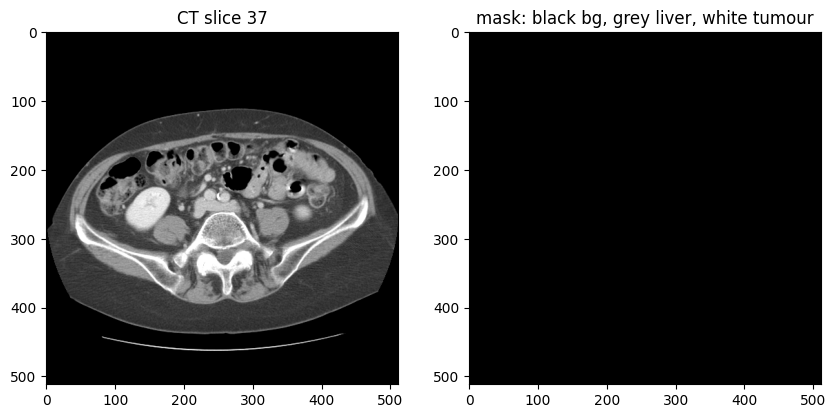

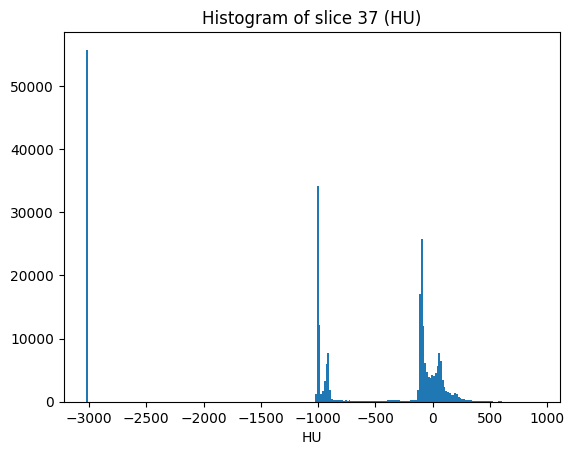

In [4]:
# show the middle slice and its mask (rot90 fixes the sideways orientation)
i = vol.shape[2] // 2
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.rot90(vol[:, :, i]), cmap="gray", vmin=-200, vmax=250)
ax[0].set_title(f"CT slice {i}")
ax[1].imshow(np.rot90(seg[:, :, i]), cmap="gray")
ax[1].set_title("mask: black bg, grey liver, white tumour")
plt.show()

# look at the histogram of the HU values: air near -1000, soft tissue near 0 to 100, bone above 300
plt.figure()
plt.hist(vol[:, :, i].ravel(), bins=256)
plt.title('Histogram of slice ' + str(i) + ' (HU)')
plt.xlabel('HU')
plt.show()

In [5]:
# find the slices that contain liver (label >= 1) and tumour (label 2)
liver_slices = []
tumour_slices = []
for i in range(seg.shape[2]):
    if np.any(seg[:, :, i] >= 1):
        liver_slices.append(i)
    if np.any(seg[:, :, i] == 2):
        tumour_slices.append(i)
print(len(liver_slices), "liver slices")
print(len(tumour_slices), "tumour slices:", tumour_slices)
# if the tumour list is empty, this patient has no tumour -> pick another patient

29 liver slices
16 tumour slices: [46, 56, 57, 58, 59, 60, 61, 62, 65, 66, 67, 68, 69, 70, 71, 72]


In [6]:
# save every tumour slice: CT (HU) as .npy, liver and tumour masks as black/white .png
chosen = tumour_slices    # all tumour slices (they also contain liver)
os.makedirs(OUT, exist_ok=True)

for i in chosen:
    ct = np.rot90(vol[:, :, i])
    s = np.rot90(seg[:, :, i])
    base = OUT + "/p" + str(PATIENT) + "_s" + str(i)
    np.save(base + "_ct.npy", ct.astype(np.float32))                      # raw HU values
    cv2.imwrite(base + "_liver.png", ((s >= 1) * 255).astype(np.uint8))   # white = liver
    cv2.imwrite(base + "_tumour.png", ((s == 2) * 255).astype(np.uint8))  # white = tumour

print("saved", len(chosen), "slices to", OUT)
print("write these in data_log.csv:", chosen)

saved

 16 slices to ../data/slices/sama
write these in data_log.csv: [46, 56, 57, 58, 59, 60, 61, 62, 65, 66, 67, 68, 69, 70, 71, 72]


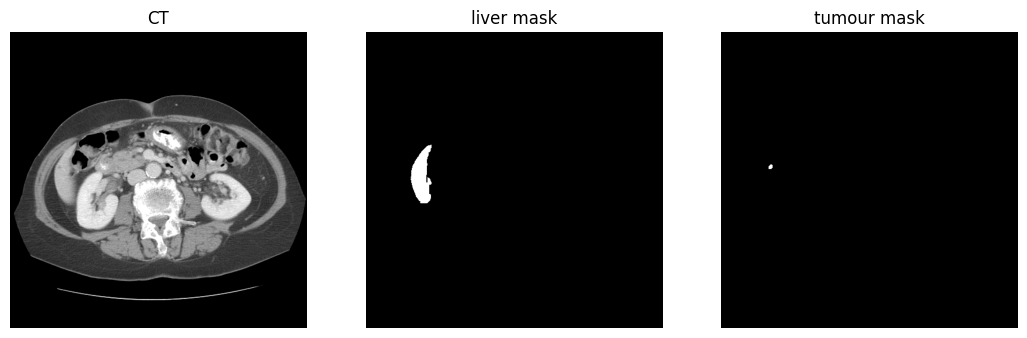

In [7]:
# read one saved slice back and show it (check the files are correct)
i = chosen[0]
ct = np.load(OUT + "/p" + str(PATIENT) + "_s" + str(i) + "_ct.npy")
liver = cv2.imread(OUT + "/p" + str(PATIENT) + "_s" + str(i) + "_liver.png", 0)
tumour = cv2.imread(OUT + "/p" + str(PATIENT) + "_s" + str(i) + "_tumour.png", 0)

check_images = [ct, liver, tumour]
check_titles = ["CT", "liver mask", "tumour mask"]
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for j in range(3):
    if check_titles[j] == "CT":
        ax[j].imshow(check_images[j], cmap="gray", vmin=-200, vmax=250)   # CT: show -200 to 250 HU
    else:
        ax[j].imshow(check_images[j], cmap="gray", vmin=0, vmax=255)      # masks: 0 or 255
    ax[j].set_title(check_titles[j])
    ax[j].axis("off")
plt.show()

**Tumour-free slices (same patient).** To test "healthy" at the level of a whole slice (does the pipeline raise a false alarm on a slice with no tumour?), a few liver slices **without** tumour are saved in a separate folder `data/slices/<name>_healthy/`, so the Phase 1-3 test sets stay unchanged. Rules: liver at least 3000 pixels (no tiny pole slices), at least 3 slices away from any tumour slice, up to 6 slices spread evenly.

In [8]:
HEALTHY_OUT = "../data/slices/" + NAME + "_healthy"
MIN_LIVER_PX = 3000
GAP = 3
N_HEALTHY = 6

# liver slices that are big enough (no tiny pole slices)
liver_ok = []
for i in range(seg.shape[2]):
    if (seg[:, :, i] >= 1).sum() >= MIN_LIVER_PX:
        liver_ok.append(i)

# keep only those with no tumour within 3 slices
free = []
for i in liver_ok:
    far_from_tumour = True
    for t in tumour_slices:
        if abs(i - t) < GAP:
            far_from_tumour = False
    if far_from_tumour:
        free.append(i)

# up to 6 slices spread evenly over the free ones
positions = np.linspace(0, len(free) - 1, min(N_HEALTHY, len(free)))
picks = np.unique(positions.round().astype(int))
healthy_slices = []
for j in picks:
    healthy_slices.append(free[j])

os.makedirs(HEALTHY_OUT, exist_ok=True)
for i in healthy_slices:
    ct = np.rot90(vol[:, :, i])
    s = np.rot90(seg[:, :, i])
    base = HEALTHY_OUT + "/p" + str(PATIENT) + "_s" + str(i)
    np.save(base + "_ct.npy", ct.astype(np.float32))
    cv2.imwrite(base + "_liver.png", ((s >= 1) * 255).astype(np.uint8))
    cv2.imwrite(base + "_tumour.png", ((s == 2) * 255).astype(np.uint8))      # all black: no tumour
print(len(free), "usable tumour-free liver slices; saved", healthy_slices, "to", HEALTHY_OUT)

5 usable tumour-free liver slices; saved [49, 50, 51, 52, 53] to ../data/slices/sama_healthy
